# Свёрточная нейронная сеть (CNN)

Цель работы — распознавание десяти видов одежды и обуви по полутоновым изображениям 28×28. Используется полный Fashion-MNIST: 60 000 исходных обучающих и 10 000 тестовых изображений. После проверки изображений выделяется Validation из исходного Train; официальный Test остаётся отдельным.

Источник: [Fashion-MNIST, Zalando Research](https://github.com/zalandoresearch/fashion-mnist).

In [ ]:
%pip install -q numpy pandas matplotlib scipy scikit-learn torch certifi

В первой кодовой ячейке устанавливаются зависимости. Ключ `-q` сокращает служебный вывод pip. При успешной установке ошибок не появляется. PyTorch используется для вычисления градиентов и пакетного обучения.

In [2]:
import os, io, zipfile, gzip, struct, hashlib, math, json
from pathlib import Path
from urllib.request import urlopen, Request
import ssl
import certifi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score, mean_absolute_error,
    mean_squared_error, r2_score)
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

Были подключены библиотеки для таблиц, графиков, разделения выборок и расчёта метрик. `torch.nn` содержит слои нейронных сетей, а `DataLoader` выдаёт пакеты примеров. Импорты сами по себе ничего не выводят.

In [3]:
get_ipython().run_line_magic("matplotlib", "inline")
DATA = Path(os.environ.get("ML_DATA_DIR", "data"))
DATA.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
def seed_all():
    np.random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)
seed_all()

def fetch(url, name, md5=None):
    path = DATA / name
    def check(file, sha256=None):
        if file.suffix == ".part" and file.stat().st_size == 0:
            raise ValueError("Пустой файл")
        if md5 and hashlib.md5(file.read_bytes()).hexdigest() != md5:
            raise ValueError("Неверная контрольная сумма MD5")
        if sha256 and hashlib.sha256(file.read_bytes()).hexdigest() != sha256:
            raise ValueError("Неверная контрольная сумма SHA-256 резервного архива")
        if name.endswith(".zip"):
            with zipfile.ZipFile(file) as archive:
                if archive.testzip() is not None:
                    raise ValueError("Повреждённый ZIP")
    if path.exists():
        try:
            check(path)
            return path
        except (OSError, ValueError, zipfile.BadZipFile) as exc:
            print(f"Кэш {name} повреждён: {exc}. Повторная загрузка.")
    sources = [(url, None)]
    if name == "bank_marketing.zip":
        # Резервная копия оригинального UCI bank.zip, содержащего bank-full.csv.
        sources.append(("https://raw.githubusercontent.com/raederhans/ca6003-bank-marketing/main/data/source/bank.zip",
                        "99d7e8eb12401ed278b793984423915411ea8df099e1795f9fefe254f513fe5e"))
    tmp = path.with_suffix(path.suffix + ".part")
    errors = []
    for address, sha256 in sources:
        for label, context in [("системные CA", ssl.create_default_context()),
                               ("certifi", ssl.create_default_context(cafile=certifi.where()))]:
            try:
                with urlopen(Request(address, headers={"User-Agent": "Python ML coursework"}),
                             timeout=120, context=context) as response, tmp.open("wb") as out:
                    while chunk := response.read(1024*1024):
                        out.write(chunk)
                check(tmp, sha256)
                tmp.replace(path)
                print(f"Загружен {name}: {address} ({label})")
                return path
            except (OSError, ValueError, zipfile.BadZipFile) as exc:
                tmp.unlink(missing_ok=True)
                errors.append(f"{address} ({label}): {exc}")
                print(errors[-1])
    raise RuntimeError(f"Не удалось безопасно скачать {name}. Проверьте дату Windows, сертификаты и соединение. "
                       f"Можно скачать оригинальный файл вручную и сохранить как {path}.\n" + "\n".join(errors))

def loader(x, y, batch=256, shuffle=False, regression=False):
    a = torch.as_tensor(np.ascontiguousarray(x), dtype=torch.float32)
    b = torch.as_tensor(np.ascontiguousarray(y), dtype=torch.float32 if regression else torch.long)
    return DataLoader(TensorDataset(a,b), batch_size=batch, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(42), num_workers=0)

def evaluate(model, batches, loss_fn, regression=False):
    model.eval(); total=0.; count=0; outputs=[]; targets=[]
    with torch.no_grad():
        for x,y in batches:
            yhat=model(x.to(DEVICE)); y=y.to(DEVICE)
            total += loss_fn(yhat,y).item()*len(y); count += len(y)
            outputs.append(yhat.cpu().numpy()); targets.append(y.cpu().numpy())
    return total/count, np.concatenate(outputs), np.concatenate(targets)

def fit_net(model, train, val, loss_fn, epochs, lr, regression=False):
    model.to(DEVICE); optim=torch.optim.Adam(model.parameters(),lr=lr)
    history=[]; best=float("inf"); best_state=None
    for epoch in range(1,epochs+1):
        model.train(); sum_loss=0.; count=0
        for x,y in train:
            x,y=x.to(DEVICE),y.to(DEVICE)
            optim.zero_grad(); pred=model(x); loss=loss_fn(pred,y)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),5.0); optim.step()
            sum_loss+=loss.item()*len(y); count+=len(y)
        vloss, vp, vy=evaluate(model,val,loss_fn,regression)
        score=float(np.sqrt(np.mean((vp-vy)**2))) if regression else float(np.mean(vp.argmax(1)==vy))
        history.append((epoch,sum_loss/count,vloss,score))
        if vloss<best:
            best=vloss; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(f"Epoch {epoch:02d}: train loss={sum_loss/count:.4f}; val loss={vloss:.4f}; val score={score:.4f}")
    model.load_state_dict(best_state)
    return pd.DataFrame(history,columns=["epoch","train_loss","val_loss","val_score"])

def chart(title,xlabel,ylabel):
    plt.title(title); plt.xlabel(xlabel); plt.ylabel(ylabel); plt.tight_layout(); plt.show(); plt.close()

def heat(a,labels,title,xlabel,ylabel,fmt):
    a=np.asarray(a); plt.figure(figsize=(9,7)); plt.imshow(a,cmap="Blues",aspect="auto"); plt.colorbar()
    plt.xticks(range(len(labels)),labels,rotation=45,ha="right"); plt.yticks(range(len(labels)),labels)
    for i in range(a.shape[0]):
        for j in range(a.shape[1]):
            plt.text(j,i,format(a[i,j],fmt),ha="center",va="center",fontsize=7,
                     color="white" if a[i,j]>a.max()*0.55 else "black")
    chart(title,xlabel,ylabel)

def size_table(train,val,test):
    assert train>=20000, "Training set must contain at least 20,000 examples"
    return {"Train":int(train),"Validation":int(val),"Test":int(test)}

def class_metrics(y,p):
    return {"Accuracy":accuracy_score(y,p),"Macro Precision":precision_score(y,p,average="macro",zero_division=0),
            "Macro Recall":recall_score(y,p,average="macro",zero_division=0),"Macro F1":f1_score(y,p,average="macro",zero_division=0)}
print("Устройство:",DEVICE)

Устройство: cpu


`fetch` сохраняет исходный файл локально, при наличии контрольной суммы проверяет целостность. Для HTTPS используются системные сертификаты или набор `certifi`; проверка сертификатов остаётся включённой. Если основной источник Bank Marketing недоступен, используется копия исходного архива `bank.zip` с проверкой SHA-256. `loader` формирует батчи без копирования примеров между выборками. В `fit_net` последовательно выполняются прямой проход, вычисление функции потерь, `backward()` и обновление весов Adam. Валидация выполняется без градиентов; сохраняется состояние с минимальной ошибкой Validation. Test здесь не используется. `size_table` проверяет наличие не менее 20 000 обучающих примеров. В выводе ячейки указывается выбранное устройство CPU или CUDA.

In [4]:
seed_all()
base="https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
files={"train-images-idx3-ubyte.gz":"8d4fb7e6c68d591d4c3dfef9ec88bf0d","train-labels-idx1-ubyte.gz":"25c81989df183df01b3e8a0aad5dffbe","t10k-images-idx3-ubyte.gz":"bef4ecab320f06d8554ea6380940ec79","t10k-labels-idx1-ubyte.gz":"bb300cfdad3c16e7a12a480ee83cd310"}
def read_idx(name):
    raw=gzip.decompress(fetch(base+name,name,files[name]).read_bytes())
    magic,count=struct.unpack(">II",raw[:8])
    if magic==2051:
        h,w=struct.unpack(">II",raw[8:16]); assert (h,w)==(28,28)
        return np.frombuffer(raw,dtype=np.uint8,offset=16).reshape(count,h,w).copy()
    assert magic==2049
    return np.frombuffer(raw,dtype=np.uint8,offset=8).reshape(count).copy()
x0=read_idx("train-images-idx3-ubyte.gz"); y0=read_idx("train-labels-idx1-ubyte.gz")
xte=read_idx("t10k-images-idx3-ubyte.gz"); yte=read_idx("t10k-labels-idx1-ubyte.gz")
labels=["Футболка","Брюки","Пуловер","Платье","Пальто","Сандалии","Рубашка","Кроссовки","Сумка","Ботинки"]
print(x0.shape,y0.shape,xte.shape,yte.shape)

Загружен train-images-idx3-ubyte.gz: https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-images-idx3-ubyte.gz (системные CA)


Загружен train-labels-idx1-ubyte.gz: https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-labels-idx1-ubyte.gz (системные CA)


Загружен t10k-images-idx3-ubyte.gz: https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-images-idx3-ubyte.gz (системные CA)


Загружен t10k-labels-idx1-ubyte.gz: https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-labels-idx1-ubyte.gz (системные CA)
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


Файлы IDX распаковываются через gzip, затем считывается двоичный заголовок: код 2051 обозначает изображения, 2049 — метки. `reshape` восстанавливает размер 28×28. Контрольные суммы проверяются перед чтением. На экране появляются формы массивов; метки представлены числами 0–9.

In [5]:
def clean_images(x,y):
    assert len(x)==len(y)
    valid=(y<10)&(x.max(axis=(1,2))>x.min(axis=(1,2)))
    print("Некорректные/однотонные:",int((~valid).sum()),"NaN:",int(np.isnan(x).sum()),"Пиксели:",x.min(),x.max())
    x,y=x[valid],y[valid]
    _, idx, counts=np.unique(x.reshape(len(x),-1),axis=0,return_index=True,return_counts=True)
    print("Повторные изображения:",int(len(x)-len(idx)))
    # Все совпадающие изображения исключены, в том числе с разными метками.
    idx=np.sort(idx[counts==1]); return x[idx],y[idx]
x0,y0=clean_images(x0,y0); xte,yte=clean_images(xte,yte)
# Не допускается совпадение пикселей между Train/Validation и Test.
test_keys={v.tobytes() for v in xte}; keep=np.array([v.tobytes() not in test_keys for v in x0]); print("Совпадения с Test:",int((~keep).sum()))
x0,y0=x0[keep],y0[keep]
i,j=train_test_split(np.arange(len(y0)),test_size=.15,stratify=y0,random_state=42)
xa,ya=x0[i],y0[i]; xb,yb=x0[j],y0[j]
sizes=size_table(len(xa),len(xb),len(xte)); print(sizes)
# Фиксированное преобразование, не оценивает параметры на Test.
a=xa[:,None].astype(np.float32)/255; b=xb[:,None].astype(np.float32)/255; c=xte[:,None].astype(np.float32)/255

Некорректные/однотонные: 0 NaN: 0 Пиксели: 0 255


Повторные изображения: 0
Некорректные/однотонные: 0 NaN: 0 Пиксели: 0 255


Повторные изображения: 0
Совпадения с Test: 0
{'Train': 51000, 'Validation': 9000, 'Test': 10000}


Проверены диапазон пикселей, NaN, соответствие числа меток, классы, однотонные и одинаковые изображения. Повторяющиеся изображения исключены, а совпадения с Test убраны из исходной обучающей части. `train_test_split` сохраняет доли классов при выделении 15% на Validation. Деление на 255 переводит пиксели из 0–255 в 0–1, `[:,None]` добавляет канал. Печатается фактический размер каждой выборки.

### Примеры изображений

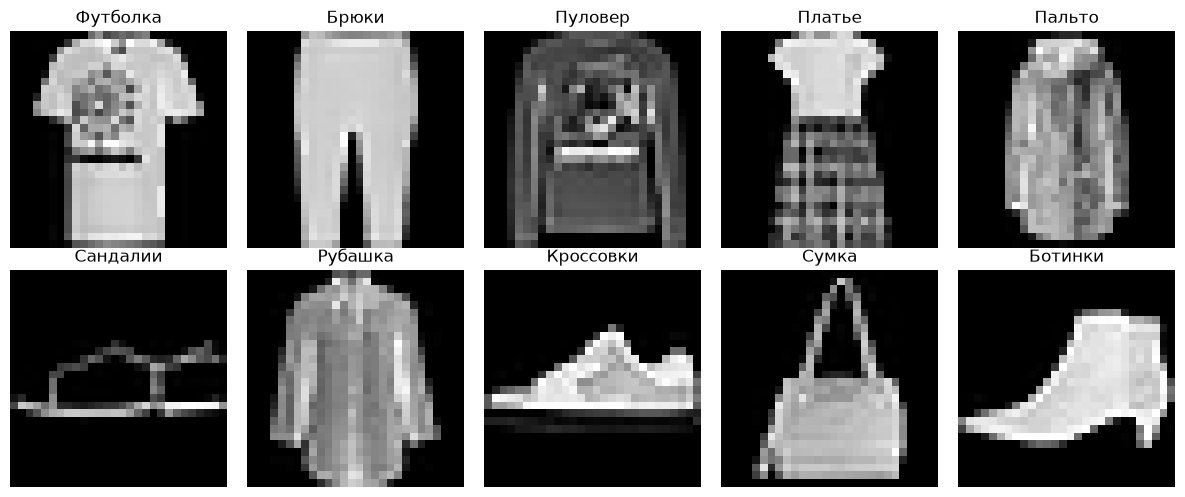

In [6]:
fig,axes=plt.subplots(2,5,figsize=(12,5));
for k,ax in enumerate(axes.ravel()):
    ax.imshow(xa[np.flatnonzero(ya==k)[0]],cmap="gray",vmin=0,vmax=255); ax.set_title(labels[k]); ax.axis("off")
plt.tight_layout(); plt.show(); plt.close()

Показано по одному изображению каждого класса из Train. Светлые пиксели соответствуют большей интенсивности. Некоторые категории, например рубашка и футболка, имеют сходные контуры, что может приводить к ошибкам.

### Распределение классов

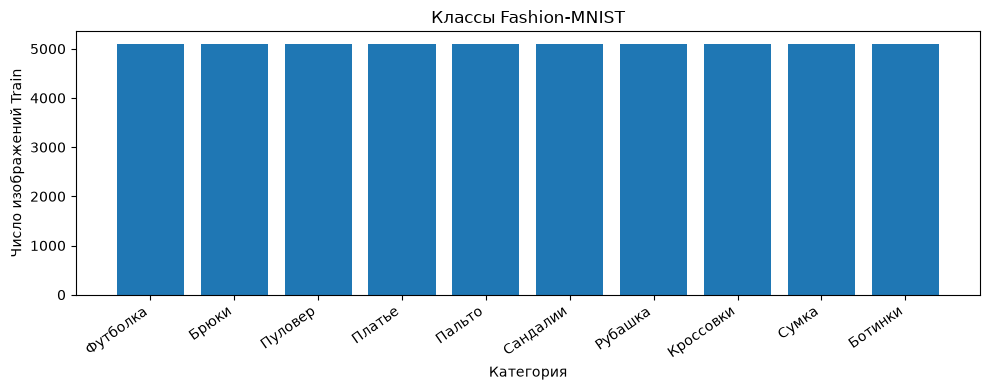

In [7]:
plt.figure(figsize=(10,4)); plt.bar(labels,np.bincount(ya,minlength=10)); plt.xticks(rotation=35,ha="right"); chart("Классы Fashion-MNIST", "Категория", "Число изображений Train")

Высота каждого столбца — число обучающих изображений данной категории после очистки. Сравниваются доли классов; если они почти одинаковы, общая Accuracy более информативна, но индивидуальные метрики всё равно необходимы.

### Гистограмма интенсивности пикселей

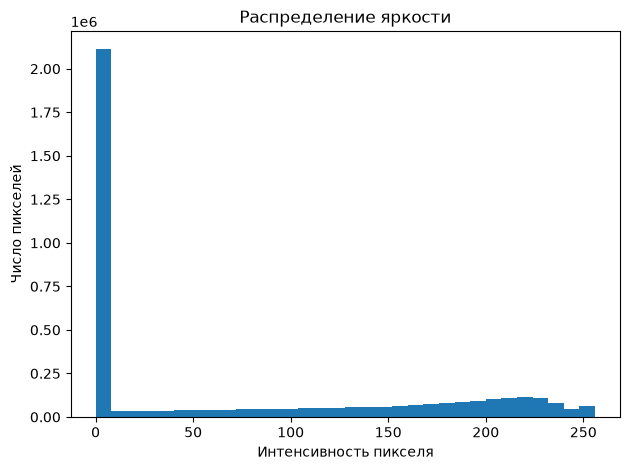

In [8]:
plt.figure(); plt.hist(xa[::10].ravel(),bins=32,range=(0,256)); chart("Распределение яркости", "Интенсивность пикселя", "Число пикселей")

Для читаемости взят каждый десятый обучающий образец; все изображения участвуют в обучении. Ось X показывает яркость, ось Y — количество пикселей. Большой столбец около нуля связан с тёмным фоном.

### Средние изображения классов

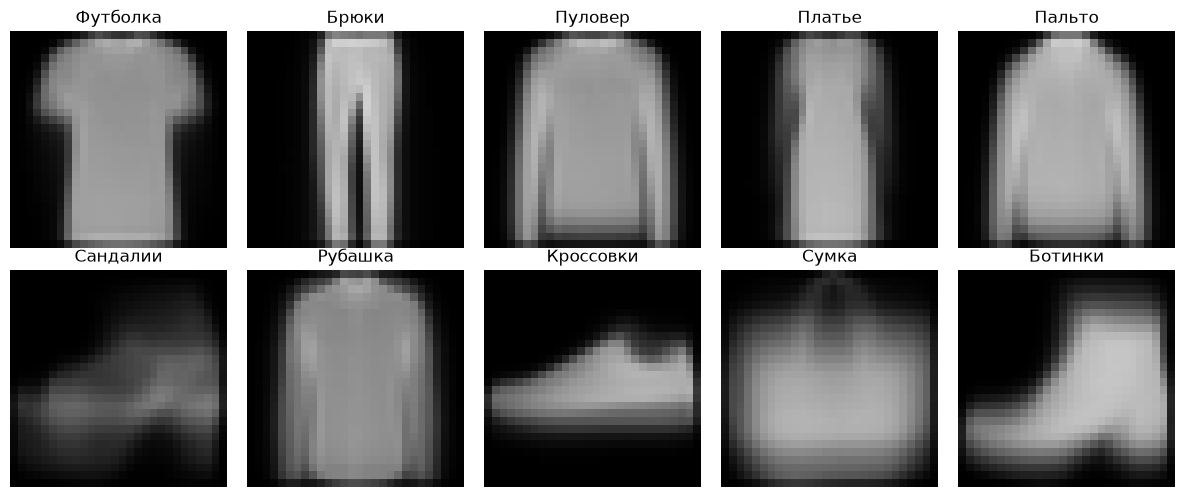

In [9]:
fig,axes=plt.subplots(2,5,figsize=(12,5));
for k,ax in enumerate(axes.ravel()):
    ax.imshow(xa[ya==k].mean(0),cmap="gray",vmin=0,vmax=255); ax.set_title(labels[k]); ax.axis("off")
plt.tight_layout(); plt.show(); plt.close()

Для каждого класса рассчитано среднее изображение по всем его обучающим примерам. Яркие области показывают места, где предмет встречается чаще; размытость возникает из-за различий формы и положения.

### Диаграмма размаха яркости

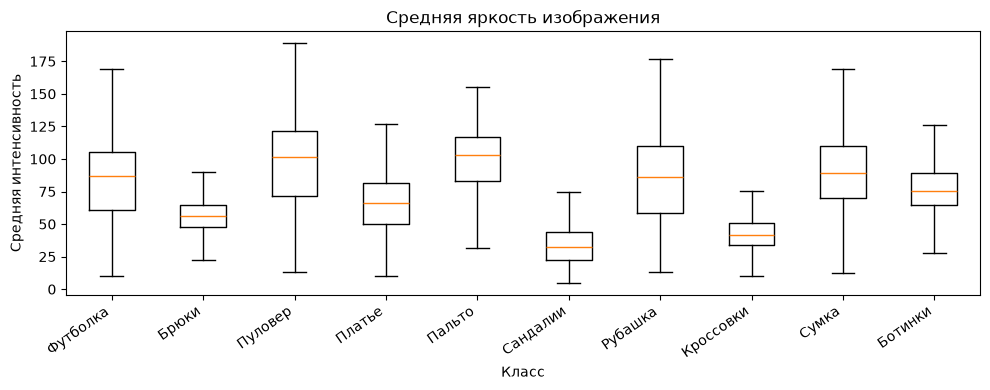

In [10]:
brightness=xa.mean(axis=(1,2)); plt.figure(figsize=(10,4)); plt.boxplot([brightness[ya==k] for k in range(10)],tick_labels=labels,showfliers=False); plt.xticks(rotation=35,ha="right"); chart("Средняя яркость изображения", "Класс", "Средняя интенсивность")

Линия в коробке — медиана средней яркости изображения, границы — квартили. Усы отражают разброс; крайние точки скрыты исключительно для читаемости, данные не удаляются. Категории могут отличаться площадью светлых областей.

### Корреляция характеристик изображений

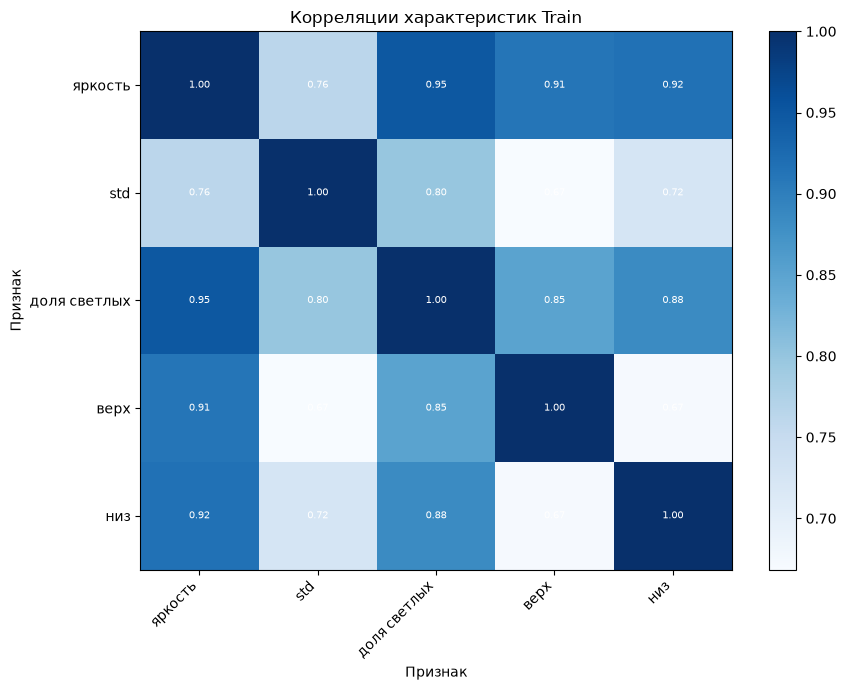

In [11]:
desc=pd.DataFrame({"яркость":brightness,"std":xa.std(axis=(1,2)),"доля светлых":(xa>128).mean(axis=(1,2)),"верх":xa[:,:14].mean(axis=(1,2)),"низ":xa[:,14:].mean(axis=(1,2))}); corr=desc.corr(); heat(corr,corr.columns,"Корреляции характеристик Train", "Признак", "Признак", ".2f")

Матрица Пирсона показывает линейные связи между агрегированными характеристиками, например средней яркостью и долей светлых пикселей. Эти характеристики предназначены только для анализа; CNN получает исходные пиксельные массивы.

In [12]:
train=loader(a,ya,batch=128,shuffle=True); val=loader(b,yb,batch=256); test=loader(c,yte,batch=256)
model=nn.Sequential(nn.Conv2d(1,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Flatten(),nn.Linear(32*7*7,64),nn.ReLU(),nn.Linear(64,10))
loss_fn=nn.CrossEntropyLoss(); print(model); print("Параметров:",sum(p.numel() for p in model.parameters()))
history=fit_net(model,train,val,loss_fn,epochs=12,lr=.001)
_, logits,true=evaluate(model,test,loss_fn); pred=logits.argmax(1); probs=torch.softmax(torch.tensor(logits),dim=1).numpy()
m=class_metrics(true,pred); print(m); print(classification_report(true,pred,target_names=labels,zero_division=0))

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=64, bias=True)
  (8): ReLU()
  (9): Linear(in_features=64, out_features=10, bias=True)
)
Параметров: 105866


Epoch 01: train loss=0.6618; val loss=0.4181; val score=0.8523


Epoch 02: train loss=0.4113; val loss=0.3576; val score=0.8698


Epoch 03: train loss=0.3524; val loss=0.3110; val score=0.8901


Epoch 04: train loss=0.3237; val loss=0.3225; val score=0.8839


Epoch 05: train loss=0.2994; val loss=0.2833; val score=0.8977


... (4 outputs left out)

Epoch 10: train loss=0.2331; val loss=0.2548; val score=0.9076


Epoch 11: train loss=0.2237; val loss=0.2370; val score=0.9157


Epoch 12: train loss=0.2131; val loss=0.2279; val score=0.9176


{'Accuracy': 0.9061, 'Macro Precision': 0.906417465484832, 'Macro Recall': 0.9061, 'Macro F1': 0.9058709428249966}
              precision    recall  f1-score   support

    Футболка       0.86      0.85      0.85      1000
       Брюки       0.99      0.97      0.98      1000
     Пуловер       0.88      0.84      0.86      1000
      Платье       0.90      0.90      0.90      1000
      Пальто       0.81      0.89      0.85      1000
    Сандалии       0.98      0.97      0.98      1000
     Рубашка       0.76      0.72      0.74      1000
   Кроссовки       0.93      0.98      0.96      1000
       Сумка       0.97      0.98      0.98      1000
     Ботинки       0.98      0.95      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



`Conv2d` применяет обучаемые ядра 3×3 к локальным областям. Два слоя формируют 16 и 32 карты признаков, MaxPool2d уменьшает пространственный размер 28→14→7. `Flatten` разворачивает карты, полносвязные слои выдают 10 логитов. CrossEntropyLoss принимает логиты и метки классов. В выводе показывается архитектура, число параметров, история 12 эпох и отчёт на официальном очищенном Test. Accuracy — доля правильных ответов; Macro Precision, Recall и F1 — средние по десяти классам.

### Кривые функции потерь

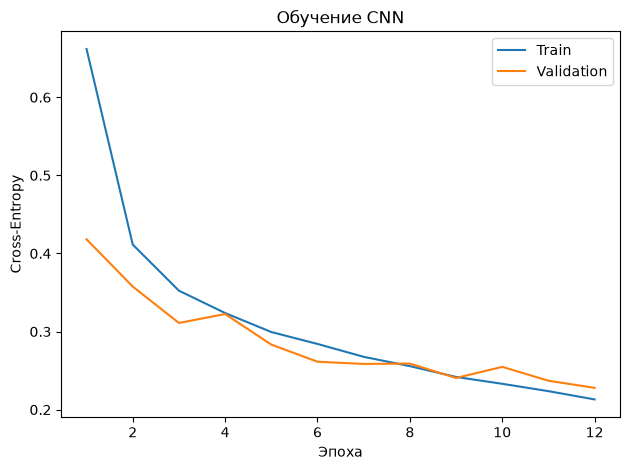

In [13]:
plt.figure(); plt.plot(history.epoch,history.train_loss,label="Train"); plt.plot(history.epoch,history.val_loss,label="Validation"); plt.legend(); chart("Обучение CNN", "Эпоха", "Cross-Entropy")

По оси X — эпохи, по Y — средняя ошибка. Разница между Train и Validation помогает обнаружить переобучение. Для Test использовано состояние с минимальной ошибкой Validation.

### Кривая точности валидации

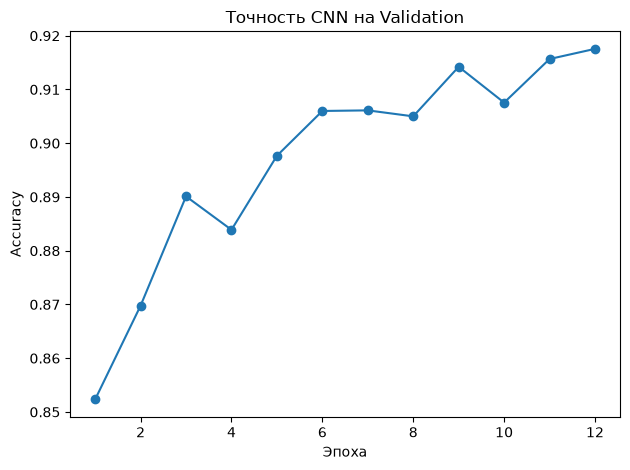

In [14]:
plt.figure(); plt.plot(history.epoch,history.val_score,marker="o"); chart("Точность CNN на Validation", "Эпоха", "Accuracy")

Каждая точка показывает долю верных предсказаний на Validation после эпохи. Рост и дальнейшее плато отражают изменение качества; это не тестовая метрика.

### Матрица ошибок

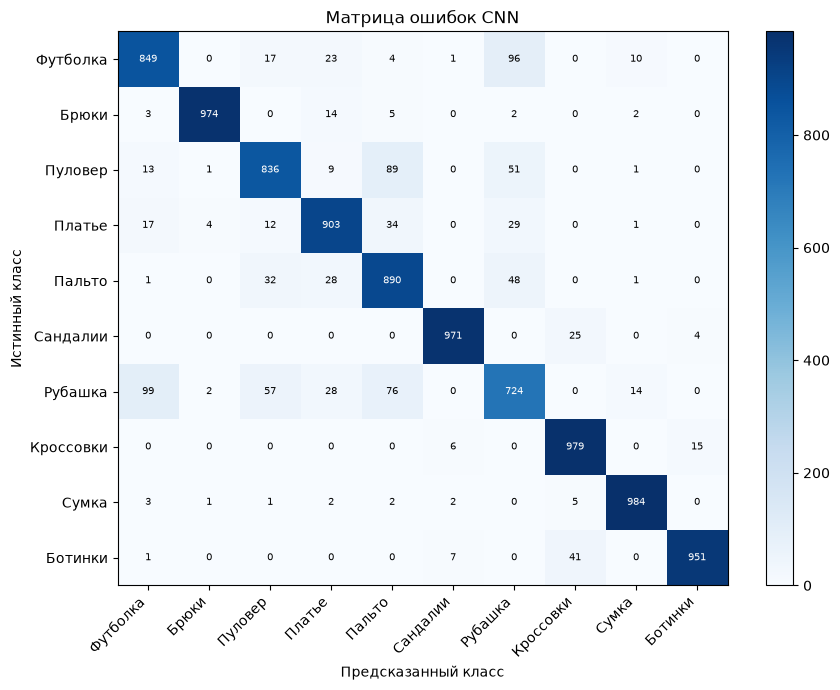

In [15]:
cm=confusion_matrix(true,pred,labels=np.arange(10)); heat(cm,labels,"Матрица ошибок CNN", "Предсказанный класс", "Истинный класс", "d")

Строки — фактические классы, столбцы — прогноз. Диагональ содержит правильные ответы, остальные ячейки показывают, какие категории сеть путает.

### Метрики по классам

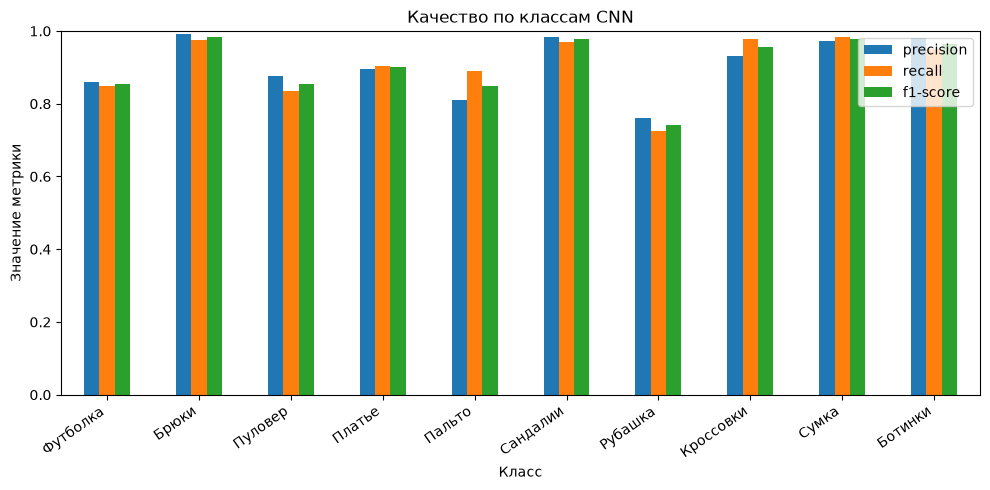

In [16]:
rep=pd.DataFrame(classification_report(true,pred,target_names=labels,output_dict=True,zero_division=0)).T.loc[labels,["precision","recall","f1-score"]]; rep.plot.bar(figsize=(10,5),ylim=(0,1)); plt.xticks(rotation=35,ha="right"); chart("Качество по классам CNN", "Класс", "Значение метрики")

По трём столбцам для каждого класса сопоставляются полнота, точность и F1. Macro F1 не позволяет частому или лёгкому классу скрыть низкое качество остальных.

### Примеры ошибок классификации

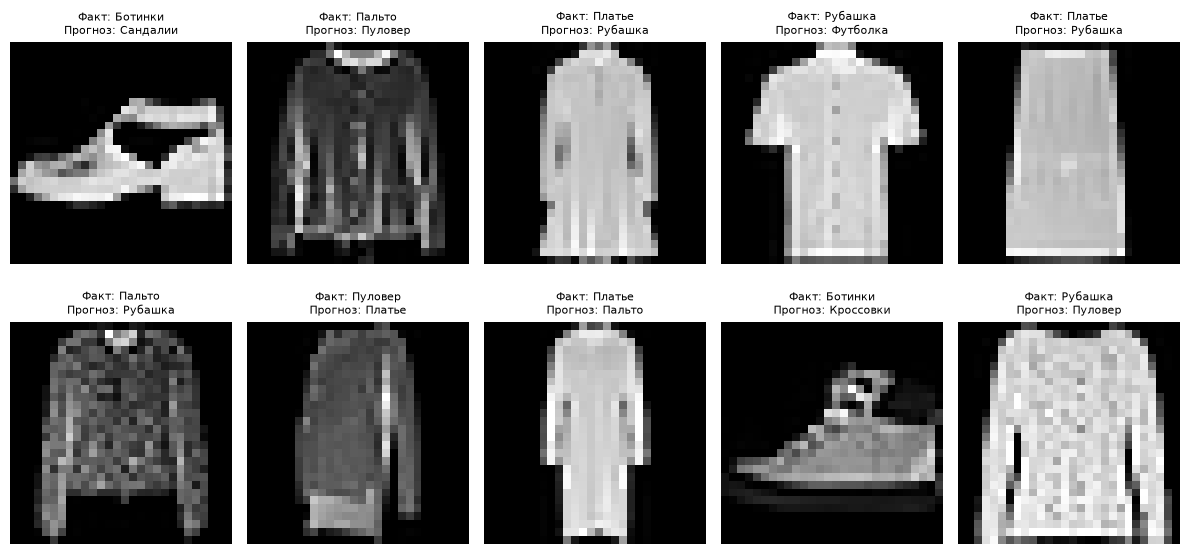

In [17]:
bad=np.flatnonzero(true!=pred); fig,axes=plt.subplots(2,5,figsize=(12,6));
for ax in axes.ravel(): ax.axis("off")
for index,ax in zip(bad[:10],axes.ravel()):
    ax.imshow(xte[index],cmap="gray"); ax.set_title(f"Факт: {labels[true[index]]}\nПрогноз: {labels[pred[index]]}",fontsize=8)
if len(bad)==0: fig.suptitle("Ошибок на Test нет")
plt.tight_layout(); plt.show(); plt.close()

Показаны первые десять ошибочных предсказаний Test, если такие имеются. Подписи сравнивают реальные и предсказанные категории. По контурам можно увидеть возможные причины путаницы, но это не доказывает причину ошибки.

### Распределение уверенности

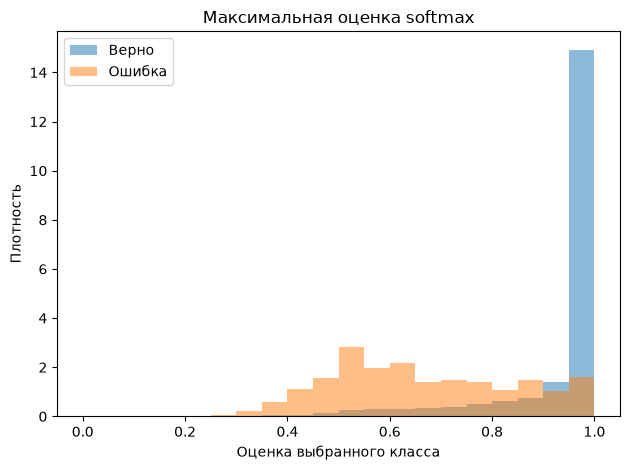

In [18]:
conf=probs.max(1); plt.figure();
for mask,label in [(true==pred,"Верно"),(true!=pred,"Ошибка")]:
    if mask.any(): plt.hist(conf[mask],bins=np.linspace(0,1,21),alpha=.5,density=True,label=label)
plt.legend(); chart("Максимальная оценка softmax", "Оценка выбранного класса", "Плотность")

Максимум softmax — оценка уверенности в выбранном классе. Сопоставляются распределения для верных и ошибочных ответов. Высокая оценка не гарантирует правильность, а softmax сам по себе не является доказательством калибровки.

In [19]:
REPORT = {"sizes": sizes, "metrics": m, "conclusion": f"Для обучения CNN использовано {sizes['Train']} отдельных изображений. На Test получены Accuracy={m['Accuracy']:.3f} и Macro F1={m['Macro F1']:.3f}. Матрица ошибок и метрики по классам позволяют оценить различия в распознавании категорий."}
print(REPORT["conclusion"])

Для обучения CNN использовано 51000 отдельных изображений. На Test получены Accuracy=0.906 и Macro F1=0.906. Матрица ошибок и метрики по классам позволяют оценить различия в распознавании категорий.


В итоговой строке выводится вывод по фактическим размерам обучающей выборки и метрикам Test.